In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from collections import Counter

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,accuracy_score,roc_curve,classification_report,f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
# from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import lightgbm as lgb
# from mlxtend.classifier import StackingCVClassifier
import warnings
warnings.filterwarnings('ignore')

In [2]:
data =  pd.read_csv('life.csv')
data

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,0,2015,1,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,0,2014,1,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,0,2013,1,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,0,2012,1,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,0,2011,1,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2933,192,2004,1,44.3,723.0,27,4.36,0.000000,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2934,192,2003,1,44.5,715.0,26,4.06,0.000000,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2935,192,2002,1,44.8,73.0,25,4.43,0.000000,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2936,192,2001,1,45.3,686.0,25,1.72,0.000000,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


In [3]:
X = data.drop(['Life expectancy '],axis = 1)
y = data['Life expectancy ']
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y ,test_size= 0.2, random_state= 42)

In [4]:
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score,mean_squared_error,mean_squared_log_error,make_scorer

model = LGBMRegressor(verbose=-1)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
r2_score(y_test, y_pred)

0.9673210997806895

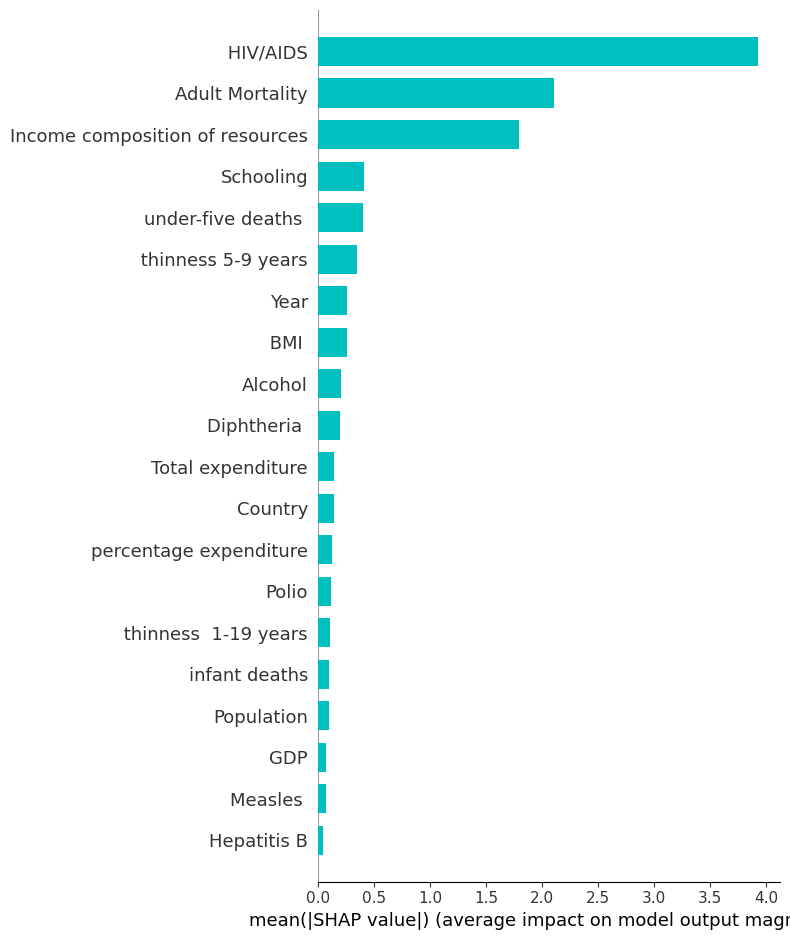

In [5]:
import time
s = time.time()

import shap
explainer = shap.Explainer(model)
shap_values = explainer.shap_values(x_test)

# Visualize SHAP values
shap.summary_plot(shap_values, x_test, plot_type="bar",color='c')

In [6]:
e = time.time()
e-s

0.9569668769836426

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already calculated shap_values

# Generate the summary plot with bar chart
shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)

In [7]:
shap_values_per_feature_sorted

Status                             0.007727
Hepatitis B                        0.047795
Measles                            0.070904
GDP                                0.077066
Population                         0.096361
infant deaths                      0.104665
 thinness  1-19 years              0.110995
Polio                              0.116651
percentage expenditure             0.127189
Country                            0.146021
Total expenditure                  0.148216
Diphtheria                         0.199324
Alcohol                            0.204691
 BMI                               0.256652
Year                               0.262975
 thinness 5-9 years                0.345827
under-five deaths                  0.399939
Schooling                          0.408282
Income composition of resources    1.791738
Adult Mortality                    2.110150
 HIV/AIDS                          3.924266
dtype: float64

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Assuming you have already calculated shap_values and x_test

# Generate the summary plot with bar chart
shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)

# 最小-最大归一化到 [0, 1] 之间
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

Status                             0.000000
Hepatitis B                        0.010230
Measles                            0.016131
GDP                                0.017704
Population                         0.022631
infant deaths                      0.024751
 thinness  1-19 years              0.026367
Polio                              0.027811
percentage expenditure             0.030502
Country                            0.035310
Total expenditure                  0.035871
Diphtheria                         0.048920
Alcohol                            0.050290
 BMI                               0.063557
Year                               0.065172
 thinness 5-9 years                0.086326
under-five deaths                  0.100143
Schooling                          0.102273
Income composition of resources    0.455507
Adult Mortality                    0.536806
 HIV/AIDS                          1.000000
dtype: float64

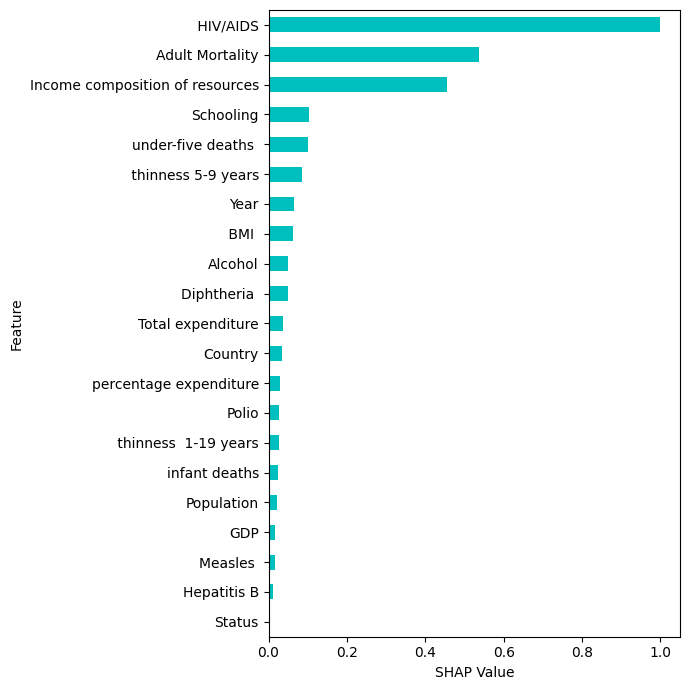

In [13]:
# Create a vertical figure for better spacing
plt.figure(figsize=(7, 7))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='c')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('shap_life_lgb_normalized.eps', format='eps', dpi=300)

plt.show()

In [16]:
import time
s = time.time()
import shap
# 确保 model.predict 的输出是一维的
def predict_fn(x):
    return model.predict(x)

explainer = shap.SamplingExplainer(predict_fn, x_test)
shap_values = explainer.shap_values(x_test)


100%|█████████████████████████████████████████| 588/588 [02:11<00:00,  4.47it/s]


In [17]:
e = time.time()
e-s

131.62546610832214

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already calculated shap_values

# Generate the summary plot with bar chart
shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

Status                             0.013578
Hepatitis B                        0.049597
Measles                            0.081992
GDP                                0.083923
Population                         0.104523
infant deaths                      0.118618
 thinness  1-19 years              0.121998
Polio                              0.129603
percentage expenditure             0.138357
Country                            0.150941
Total expenditure                  0.152139
Alcohol                            0.191672
Diphtheria                         0.236337
Year                               0.253286
 BMI                               0.340413
 thinness 5-9 years                0.352485
Schooling                          0.427615
under-five deaths                  0.468490
Income composition of resources    1.878274
Adult Mortality                    2.206210
 HIV/AIDS                          2.538431
dtype: float64

In [22]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

Status                             0.000000
Hepatitis B                        0.014266
Measles                            0.027096
GDP                                0.027861
Population                         0.036020
infant deaths                      0.041603
 thinness  1-19 years              0.042941
Polio                              0.045953
percentage expenditure             0.049420
Country                            0.054405
Total expenditure                  0.054879
Alcohol                            0.070537
Diphtheria                         0.088227
Year                               0.094939
 BMI                               0.129447
 thinness 5-9 years                0.134229
Schooling                          0.163985
under-five deaths                  0.180174
Income composition of resources    0.738536
Adult Mortality                    0.868419
 HIV/AIDS                          1.000000
dtype: float64

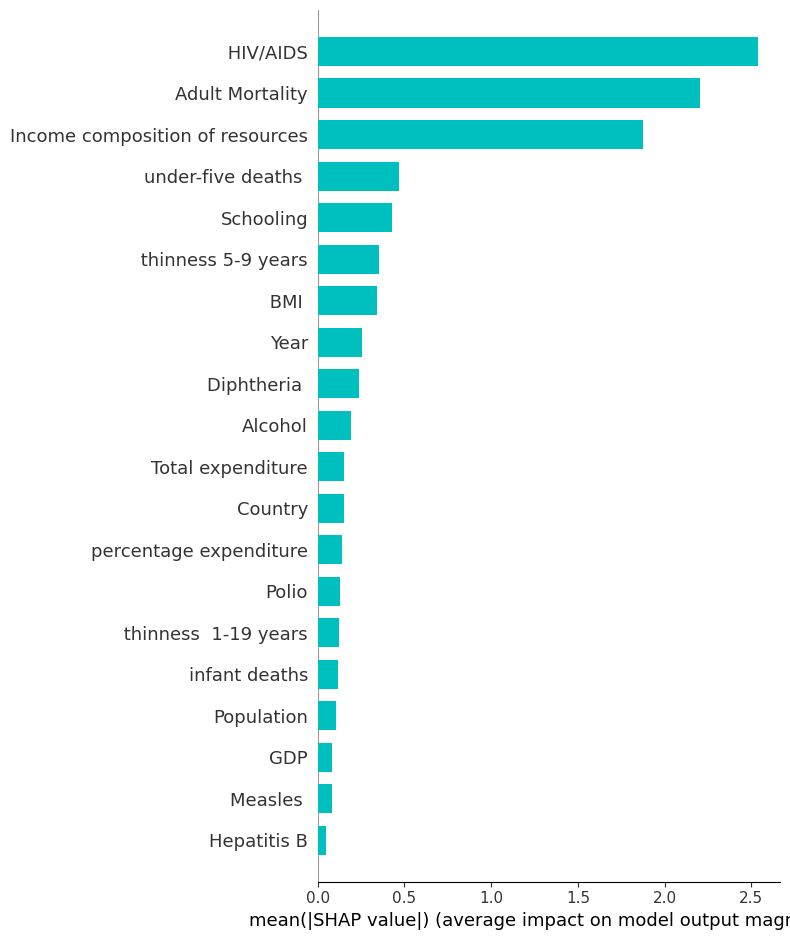

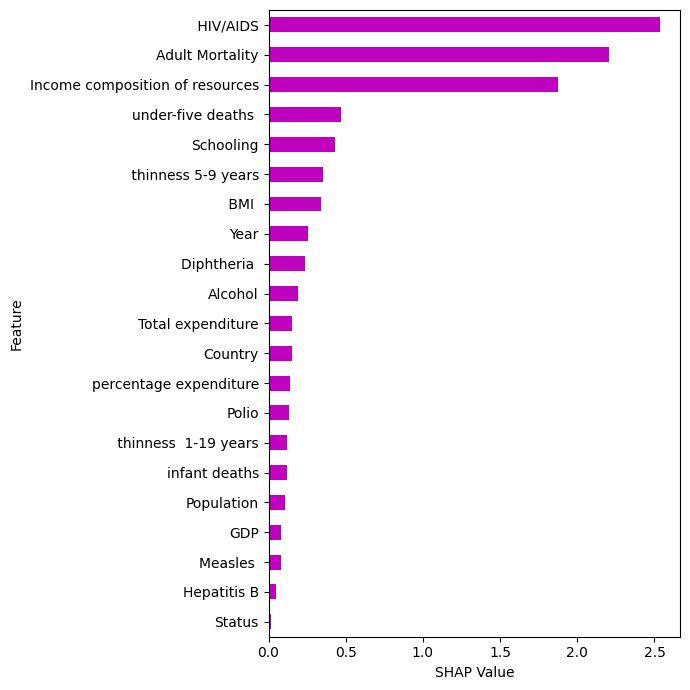

In [23]:
plt.figure(figsize=(7, 7))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_sorted.plot(kind='barh', color='m')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Samplingshap_life_lgb_normalized.eps', format='eps', dpi=300)

plt.show()

In [7]:
import time
s = time.time()

# Get feature importances
feature_importance = model.feature_importances_

# Create a DataFrame to display feature names and their corresponding importance values
feature_importance_df = pd.DataFrame({'Feature': x_train.columns, 'Importance': feature_importance})

# Sort the features based on their importance values
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Display the sorted feature importances
print(sorted_feature_importance_df)


                            Feature  Importance
3                   Adult Mortality         484
19  Income composition of resources         225
0                           Country         218
12                Total expenditure         171
5                           Alcohol         170
14                         HIV/AIDS         163
18               thinness 5-9 years         153
9                              BMI          146
20                        Schooling         136
6            percentage expenditure         128
8                          Measles          125
1                              Year         122
16                       Population         119
15                              GDP         116
13                      Diphtheria          102
10               under-five deaths          102
17             thinness  1-19 years         101
11                            Polio          84
7                       Hepatitis B          72
4                     infant deaths     

In [8]:
e = time.time()
e-s

0.23331809043884277

In [27]:
# 最小-最大归一化到 [0, 1] 之间
sorted_feature_importance_df['Normalized Importance'] = (
    sorted_feature_importance_df['Importance'] - sorted_feature_importance_df['Importance'].min()
) / (
    sorted_feature_importance_df['Importance'].max() - sorted_feature_importance_df['Importance'].min()
)

# 打印归一化后的特征重要性
sorted_feature_importance_df

,Feature,Importance,Normalized Importance
3,Adult Mortality,484,1.000000
19,Income composition of resources,225,0.461538
0,Country,218,0.446985
12,Total expenditure,171,0.349272
5,Alcohol,170,0.347193
14,HIV/AIDS,163,0.332640
18,thinness 5-9 years,153,0.311850
9,BMI,146,0.297297
20,Schooling,136,0.276507
6,percentage expenditure,128,0.259875


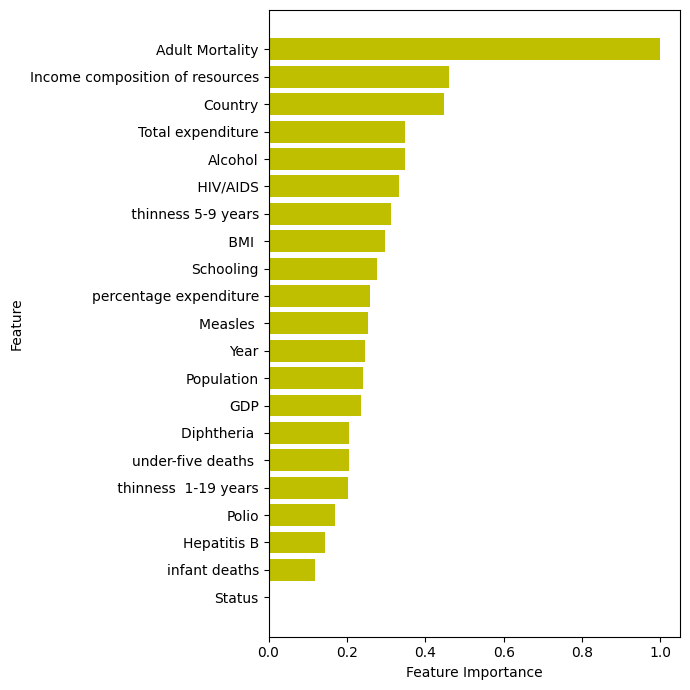

In [29]:
plt.figure(figsize=(7, 7))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Normalized Importance'], color='y')
plt.ylabel('Feature')
plt.xlabel('Feature Importance')
# plt.title('Feature Importance')
plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('feature_importance_life_lgb_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [9]:
import time
s = time.time()

from lime import lime_tabular
from lime.lime_tabular import LimeTabularExplainer

explainer = LimeTabularExplainer(x_test.values,
                                 feature_names=x_train.columns.tolist(),
                                 mode='regression')
sample_idx = 0  # Choose an index of the test set
exp = explainer.explain_instance(x_test.iloc[sample_idx].values, model.predict, num_features=len(x_test.columns))
# Extract feature values and their weights
feature_values = exp.as_list()

feature_values

[(' HIV/AIDS <= 0.10', 5.6259705212375515),
 ('69.00 < Adult Mortality <= 141.00', 3.4181992479081202),
 ('0.49 < Income composition of resources <= 0.64', -1.6639112788870787),
 ('3.50 <  thinness 5-9 years <= 7.40', -0.6473862377186893),
 ('40.50 <  BMI  <= 55.82', 0.5022121562444519),
 ('80.94 < Hepatitis B <= 86.00', 0.42739872171444243),
 ('4.00 < under-five deaths  <= 36.25', -0.3788764344801818),
 ('3.00 < infant deaths <= 26.25', -0.31564948389375),
 ('2003.00 < Year <= 2007.00', -0.24102140987392404),
 ('Alcohol <= 1.03', -0.22492483698562604),
 ('10.10 < Schooling <= 11.99', 0.17985811991494352),
 ('62.70 < percentage expenditure <= 432.32', -0.17497722501230162),
 ('3.60 <  thinness  1-19 years <= 7.50', -0.1675979232794939),
 ('Population > 12753375.12', 0.15261237744378794),
 ('Diphtheria  <= 77.75', -0.11557521753690252),
 ('611.12 < GDP <= 3193.66', -0.10238453019673037),
 ('Country > 144.00', -0.04741930402297419),
 ('Measles  > 372.75', 0.04557345046932417),
 ('77.00 <

In [10]:
e = time.time()
e-s

0.22341299057006836

In [49]:
# 提取特征值及其权重
feature_values = exp.as_map()[1]

# 根据权重的绝对值对特征进行排序
sorted_features = sorted(feature_values, key=lambda x: abs(x[1]), reverse=True)

# 提取特征名称和权重
features = [x_test.columns[i] for i, _ in sorted_features]
weights = [weight for _, weight in sorted_features]

# 打印排序后的特征及其权重（按绝对值排序）
# print("Sorted features by absolute weight (from largest to smallest):")
for feature, weight in zip(features, weights):
    print(f"Feature: {feature}, Weight: {abs(weight)}")


Feature:  HIV/AIDS, Weight: 5.81627959966998
Feature: Adult Mortality, Weight: 3.638427212686841
Feature: Income composition of resources, Weight: 1.6961043676428849
Feature:  thinness 5-9 years, Weight: 0.6129762936660083
Feature: Year, Weight: 0.5409893036512514
Feature: Diphtheria , Weight: 0.5039654224033365
Feature:  BMI , Weight: 0.47530116323795657
Feature: Schooling, Weight: 0.41518736742441015
Feature: infant deaths, Weight: 0.38720644511451985
Feature: Alcohol, Weight: 0.29580832180390204
Feature:  thinness  1-19 years, Weight: 0.22591396395748584
Feature: Hepatitis B, Weight: 0.21971678857332547
Feature: Population, Weight: 0.21867748318210886
Feature: Total expenditure, Weight: 0.20484639570389485
Feature: percentage expenditure, Weight: 0.1533879359561514
Feature: under-five deaths , Weight: 0.09045869166520343
Feature: Measles , Weight: 0.08081717502836239
Feature: Country, Weight: 0.08056673063534339
Feature: GDP, Weight: 0.07339323329211006
Feature: Polio, Weight: 0.032

In [55]:
abs_weights = [abs(weight) for weight in weights]
# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]
normalized_weights

[1.0,
 0.6255591998866918,
 0.2916132793442604,
 0.10538975700218899,
 0.0930129465718855,
 0.08664738580173001,
 0.0817191049867901,
 0.07138366722397049,
 0.0665728733426932,
 0.05085868324154953,
 0.03884166159589445,
 0.03777617372208041,
 0.03759748468669161,
 0.03521948905542952,
 0.026372173711328245,
 0.015552672479902122,
 0.013894994840507326,
 0.013851935632515812,
 0.01261858754112757,
 0.005562209105078852,
 0.0]

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 计算绝对权重
abs_weights = [abs(weight) for weight in weights]

# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]

# 绘制归一化后的特征权重条形图
plt.figure(figsize=(7, 7))
plt.barh(features, normalized_weights, color='g')  # 使用归一化后的权重
plt.xlabel('Importance')  # 修改x轴标签
plt.ylabel('Feature')
# plt.title('LIME Feature Weights (Normalized Absolute Values)')  # 修改标题
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('lime_life_lgb_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

NameError: name 'weights' is not defined

In [11]:
import time
s = time.time()

from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, x_test, y_test, n_repeats=1, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

Feature ranking:
1. feature  HIV/AIDS (20.534524)
2. feature Adult Mortality (18.729422)
3. feature Income composition of resources (9.955224)
4. feature under-five deaths  (1.402433)
5. feature Schooling (0.925435)
6. feature  thinness 5-9 years (0.692312)
7. feature Year (0.674350)
8. feature  BMI  (0.581076)
9. feature Alcohol (0.441994)
10. feature Country (0.372051)
11. feature Total expenditure (0.237338)
12. feature Diphtheria  (0.188870)
13. feature  thinness  1-19 years (0.181272)
14. feature Measles  (0.163238)
15. feature infant deaths (0.157837)
16. feature Polio (0.066060)
17. feature Population (0.061553)
18. feature percentage expenditure (0.020489)
19. feature Hepatitis B (0.002451)
20. feature Status (-0.001237)
21. feature GDP (-0.001605)


In [12]:
e = time.time()
e-s

0.20523691177368164

In [69]:
# 归一化处理
min_importance = np.min(importances)
max_importance = np.max(importances)
normalized_importances = (importances - min_importance) / (max_importance - min_importance)

# 按归一化后的重要性排序
indices = np.argsort(normalized_importances)[::-1]

# 打印归一化后的特征重要性
print("Feature ranking (normalized importance):")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({normalized_importances[indices[f]]:.6f})")

Feature ranking (normalized importance):
1. feature  HIV/AIDS (1.000000)
2. feature Adult Mortality (0.912101)
3. feature Income composition of resources (0.484844)
4. feature under-five deaths  (0.068369)
5. feature Schooling (0.045142)
6. feature  thinness 5-9 years (0.033790)
7. feature Year (0.032915)
8. feature  BMI  (0.028373)
9. feature Alcohol (0.021601)
10. feature Country (0.018195)
11. feature Total expenditure (0.011635)
12. feature Diphtheria  (0.009275)
13. feature  thinness  1-19 years (0.008905)
14. feature Measles  (0.008027)
15. feature infant deaths (0.007764)
16. feature Polio (0.003295)
17. feature Population (0.003075)
18. feature percentage expenditure (0.001076)
19. feature Hepatitis B (0.000197)
20. feature Status (0.000018)
21. feature GDP (0.000000)


In [70]:
# 创建一个数据框来存储特征及其重要性
feature_importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices],
    'Importance': normalized_importances[indices],
    'Std': std[indices]
})

# 按重要性排序
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=True)

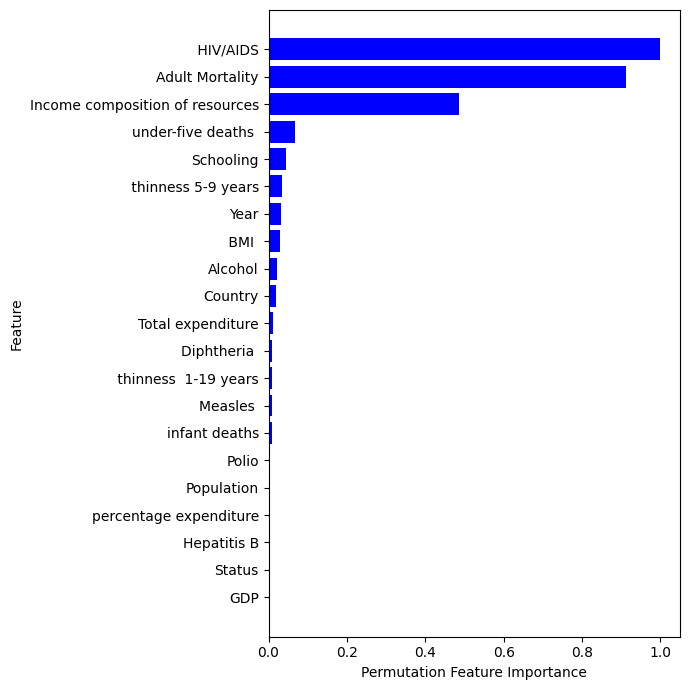

In [72]:
# 画图
plt.figure(figsize=(7, 7))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Importance'], color='b')
plt.ylabel('Feature')
plt.xlabel('Permutation Feature Importance')
# plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('Permutation_importance_life_lgb_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()